In [1]:
import pandas as pd
import networkx as nx

nodes = pd.read_csv("data/nodes.csv", dtype={"id": str})
edges = pd.read_csv("data/edges.csv", dtype={"id": str, "source": str, "target": str})

V = 20
edges["weight"] = edges["length"] / V
edges = edges.sort_values("weight", ascending=False)

In [2]:
nodes.head()

,id,type,elevation,demand,x,y
0,1003,Junction,7097.0,4.022,3219027,1415374
1,1010,Junction,6965.0,4.022,3210027,1420370
2,1012,Junction,7060.0,4.022,3216470,1415290
3,1020,Junction,7130.0,4.022,3216581,1419325
4,1021,Junction,6965.0,4.022,3210121,1420304


In [3]:
edges.head()

,id,source,target,length,diameter,type,closed,weight
1944,71737,61594,61302,3651.72,24.0,pipe,0,182.5860
193,7016,6006,6013,2718.59,24.0,pipe,0,135.9295
227,7098,6013,6076,1847.67,24.0,pipe,0,92.3835
203,7070,6035,61364,1426.95,8.0,pipe,0,71.3475
10,2031,1025,1021,1131.15,8.0,pipe,0,56.5575


In [4]:
G = nx.from_pandas_edgelist(edges, "source", "target",
                            )

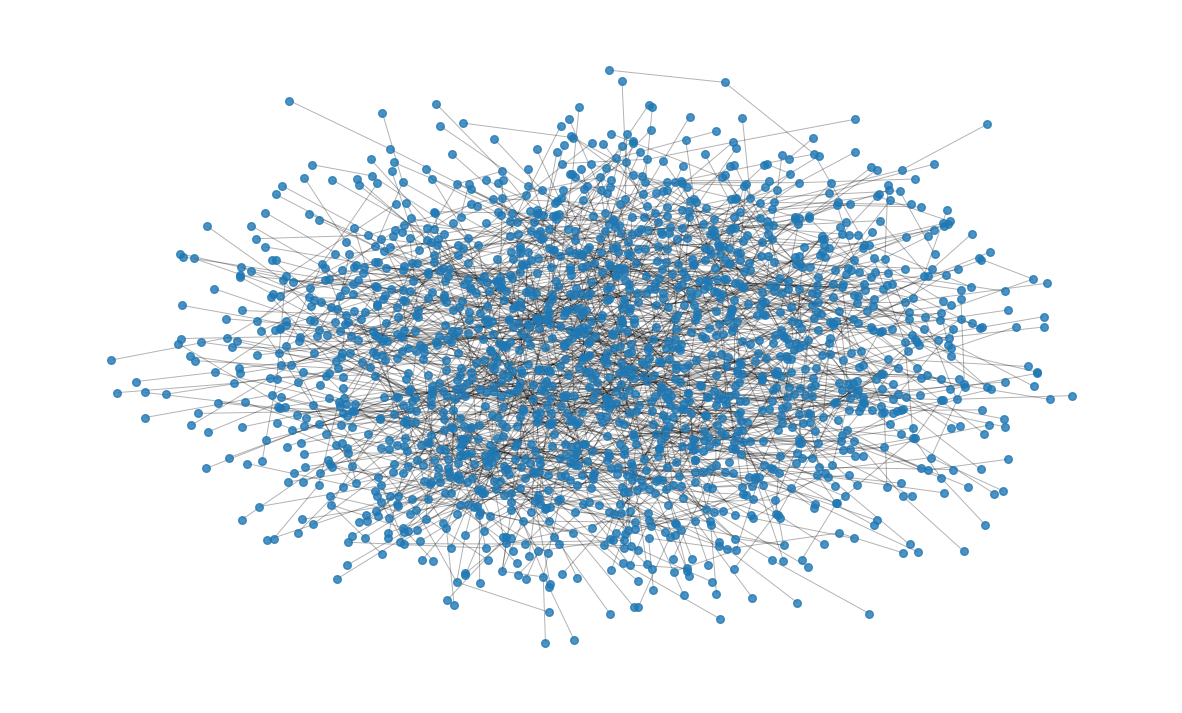

In [9]:
import matplotlib.pyplot as plt
import networkx as nx

pos = nx.spring_layout(
    G,
    k=1.5 / (len(G) ** 0.5),  # larger k spreads nodes; try 2.0 or 3.0
    iterations=10,
    seed=1721,
)

fig, ax = plt.subplots(figsize=(15, 9))
ax.axis("off")

nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.3, width=0.7)
nx.draw_networkx_nodes(G, pos, ax=ax, alpha=0.8, node_size=30)

In [10]:
nodes = G.number_of_nodes()
edges = G.number_of_edges()
print(f"Nodes: {nodes}\nEdges: {edges}")

Nodes: 1786
Edges: 1992


In [ ]:
avg_degree = 2* (edges/nodes)
avg_degree

2.230683090705487

In [ ]:
import numpy as np
avg_degree2 = np.mean([d for _, d in G.degree()])

np.float64(2.230683090705487)

In [14]:
max_degree = np.max([d for _, d  in G.degree()])
max_degree

np.int64(4)

The average degree is quite low, which is usually true for real life networks.

But unlike many other networks we don't have a hub

In [15]:
nx.density(G)

0.0012496824037565755

This is an extremely sparse network

In [ ]:
degree_centrality = nx.centrality.degree_centrality(
    G
)  # save results in a variable to use again
(sorted(degree_centrality.items(), key=lambda item: item[1], reverse=True))[:8]
#Outputs 8 highest degree centralities

[('6006', 0.002240896358543417),
 ('6013', 0.002240896358543417),
 ('6076', 0.002240896358543417),
 ('6035', 0.002240896358543417),
 ('61761', 0.002240896358543417),
 ('1023', 0.002240896358543417),
 ('1062', 0.002240896358543417),
 ('6263', 0.002240896358543417)]

In [ ]:
(sorted(G.degree, key=lambda item: item[1], reverse=True))[:8]
#All of the 8 highest degree centralities has 4 neighbors /degree of 4

[('6006', 4),
 ('6013', 4),
 ('6076', 4),
 ('6035', 4),
 ('61761', 4),
 ('1023', 4),
 ('1062', 4),
 ('6263', 4)]

Text(0, 0.5, 'Counts')

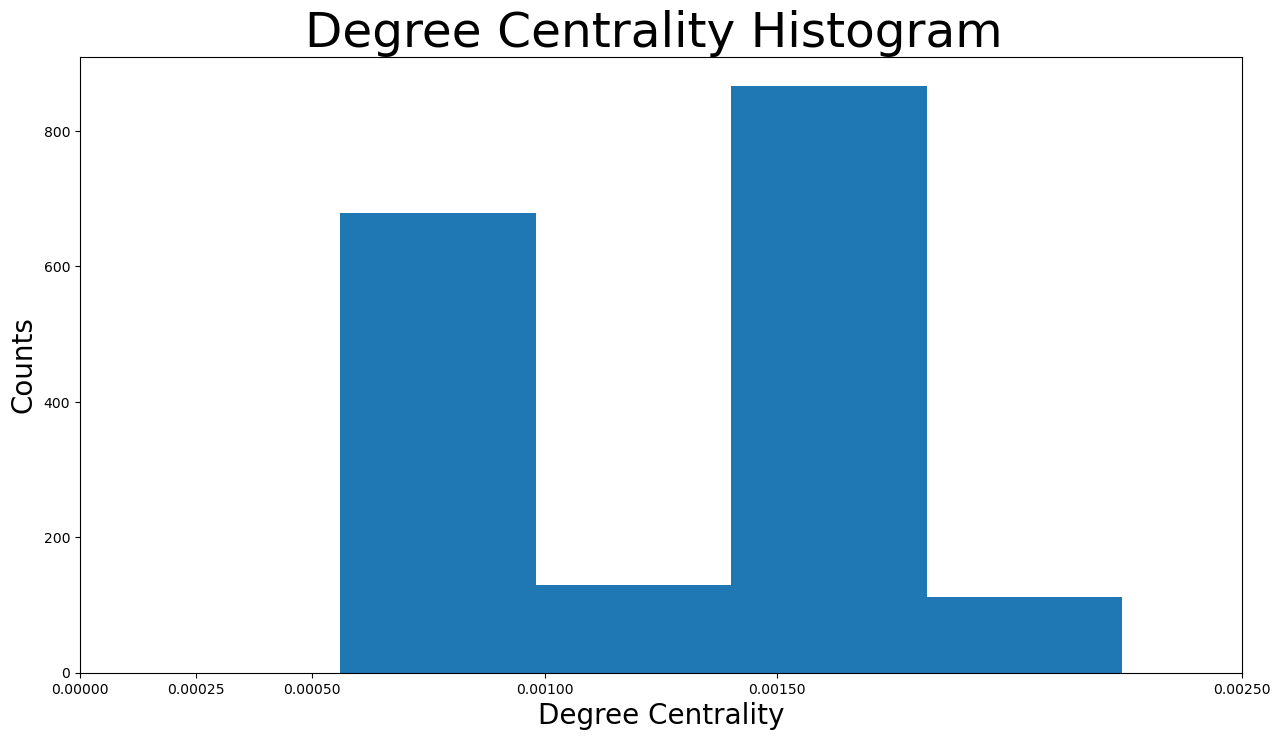

In [25]:
plt.figure(figsize=(15, 8))
plt.hist(degree_centrality.values(), bins=4)
plt.xticks(ticks=[0, 0.00025, 0.0005, 0.001, 0.0015, 0.0025])  # set the x axis ticks
plt.title("Degree Centrality Histogram ", fontdict={"size": 35}, loc="center")
plt.xlabel("Degree Centrality", fontdict={"size": 20})
plt.ylabel("Counts", fontdict={"size": 20})

In [27]:
import random as rd

rng = rd.Random(1721)  # reproducible colors
communities = list(nx.community.label_propagation_communities(G))
node_color_by_id = {}

for community in communities:
    color = f"#{rng.randrange(0x1000000):06X}"
    for node in community:
        node_color_by_id[node] = color

nodelist = list(G.nodes)
colors = [node_color_by_id[node] for node in nodelist]
len(communities)  # number of communities

704

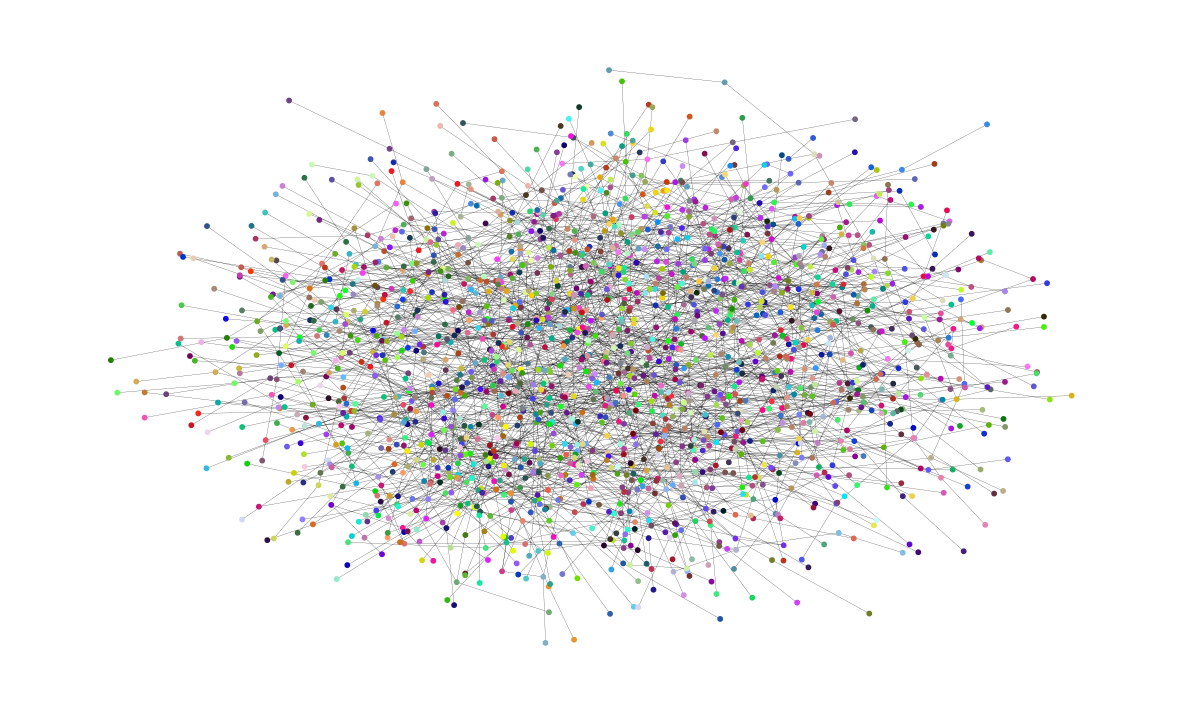

In [28]:
plt.figure(figsize=(15, 9))
plt.axis("off")
nx.draw_networkx(
    G, pos=pos, node_size=10, with_labels=False, width=0.15, node_color=colors
)